[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/danpele/MFM/blob/main/Quantlets/Ch_02/MFM_ch2_random_walk_game/MFM_ch2_random_walk_game.ipynb)

# MFM_ch2_random_walk_game

Which series is the real market? The S&P 500 (2010-2026) shown among three simulated random walks with the same drift and volatility, after Roberts (1959).

*Modelling Financial Markets (MFM), Chapter 2: Market Efficiency. Author: Daniel Traian Pele.*

In [1]:
import io
import os
import re
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy import stats
from scipy.special import gammaln
import warnings
warnings.filterwarnings('ignore')

## Style and helpers

In [2]:
# Chart style: transparent background, legend below the plot
plt.rcParams['figure.facecolor'] = 'none'
plt.rcParams['axes.facecolor'] = 'none'
plt.rcParams['savefig.facecolor'] = 'none'
plt.rcParams['savefig.transparent'] = True
plt.rcParams['axes.grid'] = False
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial', 'Helvetica']
plt.rcParams['font.size'] = 9
plt.rcParams['axes.labelsize'] = 10
plt.rcParams['axes.titlesize'] = 11
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False
plt.rcParams['axes.linewidth'] = 0.6
plt.rcParams['lines.linewidth'] = 1.1
plt.rcParams['legend.facecolor'] = 'none'
plt.rcParams['legend.framealpha'] = 0
plt.rcParams['legend.fontsize'] = 8

# Chart colours
MainBlue = '#1A3A6E'
IDAred   = '#CD0000'
Forest   = '#2E7D32'
Amber    = '#B5853F'
Orange   = '#E67E22'
Purple   = '#8E44AD'
Crimson  = '#DC3545'
Navy     = '#1F2A44'   # reference lines (no grey in charts)
BandBlue = '#C5D2E8'   # light MainBlue tint for confidence / reference bands
Gray, LightGray = Navy, BandBlue   # legacy names kept for importing scripts
GROUP_COL = {'Developed': MainBlue, 'Emerging/frontier': IDAred, 'Crypto': Amber, 'FX': Forest}

SEED = 42
TABLE_DIR = '.'


def save_fig(name):
    """Save the figure as transparent PDF and PNG in the current folder."""
    plt.savefig(f'{name}.pdf', bbox_inches='tight', transparent=True)
    plt.savefig(f'{name}.png', bbox_inches='tight', transparent=True, dpi=180)
    plt.show()
    plt.close()
    print(f"   saved {name}")


def legend_outside_bottom(ax, ncol=2, y=-0.22):
    """Place the legend outside the plot, bottom centre."""
    ax.legend(loc='upper center', bbox_to_anchor=(0.5, y), ncol=ncol, frameon=False)


## Data

In [3]:
REPO_RAW = 'https://raw.githubusercontent.com/danpele/MFM/main/data/market/'
# local copy of the course data, if the notebook runs inside the repository
MARKET_DIR = next((os.path.join(d, 'data', 'market') for d in ('.', '..', '../..', '../../..')
                   if os.path.isdir(os.path.join(d, 'data', 'market'))), '')
END = '2026-09-18'

# name -> (symbol, label, group, start date, days per year)
MARKETS = {
    'sp500':  ('GSPC.INDX',     'S&P 500 (US)',          'Developed', '2000-01-01', 252),
    'stoxx':  ('STOXX50E.INDX', 'Euro Stoxx 50',         'Developed', '2000-01-01', 252),
    'nikkei': ('N225.INDX',     'Nikkei 225 (Japan)',    'Developed', '2000-01-01', 252),
    'hsi':    ('HSI.INDX',      'Hang Seng (HK)',        'Developed', '2000-01-01', 252),
    'bet':    ('BET',           'BET (Romania)',         'Emerging/frontier', '2000-01-01', 252),
    'wig20':  ('WIG20.INDX',    'WIG20 (Poland)',        'Emerging/frontier', '2000-01-01', 252),
    'bux':    ('BUX.INDX',      'BUX (Hungary)',         'Emerging/frontier', '2000-01-01', 252),
    'px':     ('PX.INDX',       'PX (Czechia)',          'Emerging/frontier', '2000-01-01', 252),
    'xu100':  ('XU100.INDX',    'BIST 100 (Turkey)',     'Emerging/frontier', '2000-01-01', 252),
    'bvsp':   ('BVSP.INDX',     'Bovespa (Brazil)',      'Emerging/frontier', '2000-01-01', 252),
    'mxx':    ('MXX.INDX',      'IPC (Mexico)',          'Emerging/frontier', '2000-01-01', 252),
    'nsei':   ('NSEI.INDX',     'Nifty 50 (India)',      'Emerging/frontier', '2000-01-01', 252),
    'ssec':   ('SSEC.INDX',     'Shanghai (China)',      'Emerging/frontier', '2000-01-01', 252),
    'btc':    ('BTC-USD.CC',    'Bitcoin',               'Crypto', '2014-09-17', 365),
    'eth':    ('ETH-USD.CC',    'Ethereum',              'Crypto', '2016-01-01', 365),
    'eurron': ('REF:EUR',       'EUR/RON (reference rate)', 'FX', '2005-07-01', 252),
}

LABELS = {k: v[1] for k, v in MARKETS.items()}
GROUPS = {k: v[2] for k, v in MARKETS.items()}
PERIODS = {k: v[4] for k, v in MARKETS.items()}

_CACHE = {}


def artificial_fill(d):
    """Rows that repeat the previous close and show no trading: an artificial non-trading-day fill.

    A repeated close is a fill only if the row itself shows no trading: zero volume (for files that report
    volume), no intraday range (open = high = low = close) or a copy of the previous row in every field. A
    repeated close on a day with volume and an intraday range is a genuine unchanged close (a zero return)
    and is kept. Files with closes only (the BET) give no such evidence, so every row is kept.
    """
    repeat = d['close'].diff() == 0
    no_trade = pd.Series(False, index=d.index)
    if 'volume' in d and (d['volume'] > 0).mean() > 0.5:
        no_trade |= d['volume'].fillna(0) <= 0
    if {'open', 'high', 'low'} <= set(d.columns):
        no_trade |= (d['open'] == d['high']) & (d['high'] == d['low']) & (d['low'] == d['close'])
        fields = [c for c in ['open', 'high', 'low', 'close', 'volume'] if c in d]
        no_trade |= (d[fields] == d[fields].shift()).all(axis=1)
    return repeat & no_trade


def read_market(symbol):
    """Daily price table of one series (local copy of the course data, otherwise the GitHub repository)."""
    fname = f'{symbol}.csv'
    path = os.path.join(MARKET_DIR, fname)
    src = path if os.path.exists(path) else REPO_RAW + fname
    try:
        return pd.read_csv(src, index_col='date', parse_dates=True).sort_index()
    except Exception as exc:
        raise RuntimeError(f'Could not load {fname} from {src}; check the course data folder or internet connection.') from exc


def read_reference_rate(currency='EUR', start='2005-07-01', end=END):
    """Official RON reference rate (BNR annual XML archives)."""
    key = (currency, start, end)
    if key in _CACHE:
        return _CACHE[key]
    rows = []
    for y in range(int(start[:4]), int(end[:4]) + 1):
        url = f'https://curs.bnr.ro/files/xml/years/nbrfxrates{y}.xml'
        try:
            xml = urllib.request.urlopen(urllib.request.Request(url, headers={'User-Agent': 'Mozilla'}),
                                         timeout=60).read().decode()
        except Exception as exc:
            raise RuntimeError(f'Could not load BNR reference rates for {y}: {url}. Internet access is required.') from exc
        for d, body in re.findall(r'<Cube date="([\d-]+)">(.*?)</Cube>', xml, re.S):
            m = re.search(rf'<Rate currency="{currency}">([\d.]+)</Rate>', body)
            if m:
                rows.append((d, float(m.group(1))))
    s = pd.DataFrame(rows, columns=['date', 'close']).drop_duplicates('date').set_index('date')['close']
    s.index = pd.to_datetime(s.index)
    _CACHE[key] = s.sort_index().loc[start:end]
    return _CACHE[key]


def load_close(name, start=None, end=END):
    """Daily closing price, cleaned with the chapter conventions."""
    symbol, _, group, start0, _ = MARKETS[name]
    start = start or start0
    if symbol.startswith('REF:'):
        return read_reference_rate(symbol.split(':')[1], start=start, end=end).rename(name)
    d = read_market(symbol).loc[start:end]
    d = d[d['close'] > 0].dropna(subset=['close'])
    if group != 'Crypto':
        d = d[d.index.dayofweek < 5]          # no weekend quotes
        d = d[~artificial_fill(d)]            # non-trading days filled with the previous price
    return d['close'].rename(name)


def complete_months(x):
    """Drop the incomplete final month (last observation before the last business day of the month):
    the monthly analyses and the turn-of-the-month effect use complete months only."""
    last = x.index[-1]
    if last + pd.offsets.BMonthEnd(0) != last:
        x = x[x.index < last.to_period('M').start_time]
    return x


def log_returns(name, start=None, end=END):
    """Log returns on the series' own calendar."""
    return np.log(load_close(name, start, end)).diff().dropna().rename(name)


rets = {k: log_returns(k) for k in MARKETS}
ORDER = list(MARKETS)
for k in ORDER:
    print(f'{LABELS[k]:26s}', rets[k].index[0].date(), '->', rets[k].index[-1].date(), len(rets[k]), 'obs')

S&P 500 (US)               2000-01-04 -> 2026-09-18 6717 obs
Euro Stoxx 50              2000-01-04 -> 2026-09-18 6836 obs
Nikkei 225 (Japan)         2000-01-05 -> 2026-09-18 6545 obs
Hang Seng (HK)             2000-01-04 -> 2026-09-18 6583 obs
BET (Romania)              2000-01-06 -> 2026-09-18 6670 obs
WIG20 (Poland)             2000-01-04 -> 2026-09-18 6686 obs
BUX (Hungary)              2000-01-05 -> 2026-09-18 6666 obs
PX (Czechia)               2000-01-06 -> 2026-09-18 6697 obs
BIST 100 (Turkey)          2000-01-05 -> 2026-09-18 6692 obs
Bovespa (Brazil)           2000-01-04 -> 2026-09-18 6622 obs
IPC (Mexico)               2000-01-04 -> 2026-09-18 6735 obs
Nifty 50 (India)           2000-01-04 -> 2026-09-18 6613 obs
Shanghai (China)           2000-01-05 -> 2026-09-18 6474 obs
Bitcoin                    2014-09-18 -> 2026-09-18 4384 obs
Ethereum                   2016-01-02 -> 2026-09-18 3913 obs
EUR/RON (reference rate)   2005-07-05 -> 2026-09-18 5352 obs


## Efficiency tests

Random-walk increments (returns): RW1 means independent and identically distributed increments; RW2 permits their distributions to differ while retaining independence; RW3 requires zero serial covariance and permits dependence in higher moments. The homoskedastic z statistic uses RW1-type assumptions; robust z* allows heteroskedasticity under RW3 plus the regularity conditions needed for asymptotic inference. A rejection addresses those return restrictions, not all forms of market efficiency.

VR denotes variance ratio; i.i.d. means independent and identically distributed. Standard errors (SE) describe estimator uncertainty. OLS means ordinary least squares; HAC denotes heteroskedasticity- and autocorrelation-consistent standard errors. DFA is detrended fluctuation analysis, and R/S is rescaled-range analysis. An autoregressive model of order one is denoted AR(1); abnormal returns in the event-study section instead use AR with a time subscript, and their sum is the cumulative abnormal return (CAR). Chow–Denning (CD) combines horizons using the Studentized Maximum Modulus (SMM) distribution.

In [4]:
def variance_ratio(r, q):
    """Overlapping VR(q) with the Lo-MacKinlay (1988) bias corrections.

    Returns (VR, homoskedastic z, heteroskedasticity-robust z*).
    """
    x = np.asarray(r, dtype=float)
    T = len(x)
    mu = x.mean()
    e = x - mu
    var_a = (e ** 2).sum() / (T - 1)
    agg = np.convolve(x, np.ones(q), mode='valid') - q * mu        # overlapping q-period sums
    m = q * (T - q + 1) * (1 - q / T)
    var_c = (agg ** 2).sum() / m
    vr = var_c / var_a
    z_homo = (vr - 1) / np.sqrt(2 * (2 * q - 1) * (q - 1) / (3 * q * T))
    den = (e ** 2).sum() ** 2
    theta = 0.0
    for j in range(1, q):
        delta = T * (e[j:] ** 2 * e[:-j] ** 2).sum() / den
        theta += (2 * (q - j) / q) ** 2 * delta
    z_star = np.sqrt(T) * (vr - 1) / np.sqrt(theta)
    return vr, z_homo, z_star


def chow_denning(r, qs=(2, 5, 10, 20)):
    """Chow-Denning multiple test: max |z*(q)|; p-value from the studentized maximum modulus (infinite df)."""
    zs = [variance_ratio(r, q)[2] for q in qs]
    zmax = np.max(np.abs(zs))
    p = 1 - (2 * stats.norm.cdf(zmax) - 1) ** len(qs)
    return zmax, p, zs


def runs_test(r):
    """Number of sign runs (zeros dropped), with its mean and variance under independence."""
    s = np.sign(np.asarray(r, dtype=float))
    s = s[s != 0]
    n1, n2 = (s > 0).sum(), (s < 0).sum()
    n = n1 + n2
    runs = 1 + (s[1:] != s[:-1]).sum()
    mean = 2 * n1 * n2 / n + 1
    var = 2 * n1 * n2 * (2 * n1 * n2 - n) / (n ** 2 * (n - 1))
    z = (runs - mean) / np.sqrt(var)
    return runs, mean, z, 2 * (1 - stats.norm.cdf(abs(z)))


def robust_ljung_box(r, m=10):
    """Ljung-Box Q(m) and Q~(m) with the robust variance tau_k = sum e_t^2 e_{t-k}^2 / (sum e_t^2)^2."""
    e = np.asarray(r, dtype=float) - np.mean(r)
    T = len(e)
    s2 = (e ** 2).sum()
    q_lb, q_rob = 0.0, 0.0
    for k in range(1, m + 1):
        rho = (e[k:] * e[:-k]).sum() / s2
        tau = (e[k:] ** 2 * e[:-k] ** 2).sum() / s2 ** 2
        q_lb += T * (T + 2) * rho ** 2 / (T - k)
        q_rob += rho ** 2 / tau
    return q_lb, 1 - stats.chi2.cdf(q_lb, m), q_rob, 1 - stats.chi2.cdf(q_rob, m)


def _rs(x):
    y = np.cumsum(x - x.mean())
    s = x.std(ddof=0)
    return (y.max() - y.min()) / s if s > 0 else np.nan


def expected_rs(n):
    """E[R/S] for i.i.d. noise (Anis & Lloyd, 1976)."""
    if n <= 340:
        f = np.exp(gammaln((n - 1) / 2) - gammaln(n / 2)) / np.sqrt(np.pi)
    else:
        f = 1 / np.sqrt(n * np.pi / 2)
    i = np.arange(1, n)
    return f * np.sum(np.sqrt((n - i) / i))


def _integer_log_scales(first, last, count):
    """Floor log-spaced scales; snap floating-point roundoff at exact integers."""
    raw = np.logspace(np.log10(first), np.log10(last), count)
    nearest = np.rint(raw)
    tolerance = 8 * np.spacing(np.maximum(1.0, np.abs(raw)))
    stable = np.where(np.abs(raw - nearest) <= tolerance, nearest, raw)
    return np.unique(np.floor(stable).astype(int))


def rs_hurst(r, min_n=10, n_sizes=20):
    """H from the slope of log(R/S) on log(n) (Hurst, 1951) and the Anis-Lloyd corrected H (slope of log(R/S) - log E[R/S] on log n, plus 0.5)."""
    x = np.asarray(r, dtype=float)
    T = len(x)
    sizes = _integer_log_scales(min_n, T // 4, n_sizes)
    rs, ers = [], []
    for n in sizes:
        k = T // n
        vals = [_rs(x[i * n:(i + 1) * n]) for i in range(k)]
        rs.append(np.nanmean(vals))
        ers.append(expected_rs(n))
    ls, lrs, lers = np.log(sizes), np.log(rs), np.log(ers)
    h = np.polyfit(ls, lrs, 1)[0]
    h_al = 0.5 + np.polyfit(ls, lrs - lers, 1)[0]
    return h, h_al, pd.DataFrame({'n': sizes, 'rs': rs, 'expected_rs': ers})


def lo_modified_rs(r, q=None):
    """Lo's (1991) statistic V = Q_T / sqrt(T); under H0 (no long memory) V lies in [0.809, 1.862] with 95% probability."""
    x = np.asarray(r, dtype=float)
    T = len(x)
    e = x - x.mean()
    if q is None:                                   # Andrews (1991) bandwidth for an AR(1)
        rho = np.corrcoef(e[1:], e[:-1])[0, 1]
        q = int(np.floor((3 * T / 2) ** (1 / 3) * abs(2 * rho / (1 - rho ** 2)) ** (2 / 3)))
    s2 = (e ** 2).mean()
    for j in range(1, q + 1):
        w = 1 - j / (q + 1)
        s2 += 2 * w * (e[j:] * e[:-j]).sum() / T
    y = np.cumsum(e)
    Q = (y.max() - y.min()) / np.sqrt(s2)
    return Q / np.sqrt(T), q


def dfa_hurst(r, min_box=10, n_sizes=18, max_frac=0.25):
    """DFA-1 exponent: slope of log F(n) on log n for the cumulative profile of demeaned returns."""
    x = np.asarray(r, dtype=float)
    y = np.cumsum(x - x.mean())
    T = len(y)
    sizes = _integer_log_scales(min_box, int(T * max_frac), n_sizes)
    F = []
    for n in sizes:
        k = T // n
        seg = y[:k * n].reshape(k, n)
        t = np.arange(n)
        A = np.vstack([t, np.ones(n)]).T
        coef, *_ = np.linalg.lstsq(A, seg.T, rcond=None)
        resid = seg.T - A @ coef
        F.append(np.sqrt((resid ** 2).mean()))
    return np.polyfit(np.log(sizes), np.log(F), 1)[0], pd.DataFrame({'n': sizes, 'F': F})


def rolling_stat(r, func, window=500, step=21):
    """Apply func on rolling windows of `window` observations, every `step` observations."""
    x = r.values
    idx, out = [], []
    for end in range(window, len(x) + 1, step):
        idx.append(r.index[end - 1])
        out.append(func(x[end - window:end]))
    return pd.Series(out, index=idx)

## Analysis

In [5]:
def fig_random_walk_game(seed=7):
    """S&P 500 2010-2026 among three random walks with the same drift and volatility."""
    p = load_close('sp500', start='2010-01-01')
    r = np.log(p).diff().dropna()
    rng = np.random.default_rng(seed)
    real_pos = rng.integers(0, 4)
    fig, axes = plt.subplots(2, 2, figsize=(7.2, 3.8), sharex=True)
    for i, ax in enumerate(axes.flat):
        if i == real_pos:
            path = np.log(p.values / p.values[0])
        else:
            sim = rng.normal(r.mean(), r.std(), len(r))
            path = np.concatenate([[0], np.cumsum(sim)])
        ax.plot(np.arange(len(path)), np.exp(path), color=MainBlue, lw=0.7)
        ax.set_title(f'Series {"ABCD"[i]}', fontsize=9, loc='left')
        ax.set_xticks([])
        ax.set_ylabel('Value of 1 USD\n(start = 1)', fontsize=8)
    fig.suptitle('One of these is the S&P 500 (2010-2026); three are simulated random walks with the same drift and volatility',
                 fontsize=8.5, x=0.02, ha='left')
    plt.tight_layout()
    save_fig('ch2_random_walk_game')
    pd.Series({'real_series': 'ABCD'[real_pos]}).to_csv(os.path.join(TABLE_DIR, 'ch2_random_walk_game_answer.csv'))
    return 'ABCD'[real_pos]

## Run

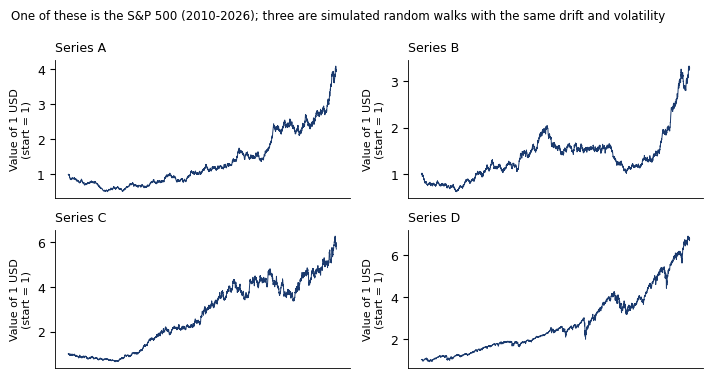

   saved ch2_random_walk_game
real series: D


In [6]:
print('real series:', fig_random_walk_game())

![ch2_random_walk_game](./ch2_random_walk_game.png)

Output: `ch2_random_walk_game.pdf`